# Lab 4: Regression Analysis with Regularization Techniques

**Student Name:** Anusha Pittala

**Course:** MSCS-634-M50 – Advanced Big Data and Data Mining

**University:** University of the Cumberlands

**Semester:** Fall 2026

## Objective

The objective of this lab is to implement and evaluate Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression using the Diabetes dataset from scikit-learn.

The models will be compared using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R²). Visualizations will help explain model accuracy, overfitting, underfitting, and the effects of regularization.

## Step 1: Data Preparation

In this step, the Diabetes dataset is loaded and explored. The dataset includes 442 patient observations, 10 baseline input features, and a quantitative target measuring diabetes disease progression one year after baseline.

The dataset will be checked for missing values, descriptive statistics, feature distributions, and relationships between variables.

In [1]:
# Import libraries for data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset and regression models
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

# Import model evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Set visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Store model results for comparison
results = []

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
# Load the Diabetes dataset
diabetes = load_diabetes()

# Convert feature data into a DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Add the target column
df["target"] = diabetes.target

# Display dataset dimensions and first five rows
print("Dataset shape:", df.shape)
print("\nFeature names:", diabetes.feature_names)

display(df.head())

Dataset shape: (442, 11)

Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Display dataset information
print("Dataset Information:")
df.info()

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Descriptive Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate Rows: 0


### Data Cleaning and Preparation

The dataset was checked for missing values and duplicate observations. No missing values or duplicate rows were found, so no imputation or duplicate removal was necessary.

The scikit-learn Diabetes dataset provides numerical features that have already been scaled. The original feature values are retained for the initial regression models, while additional standardization is applied inside model pipelines where appropriate.

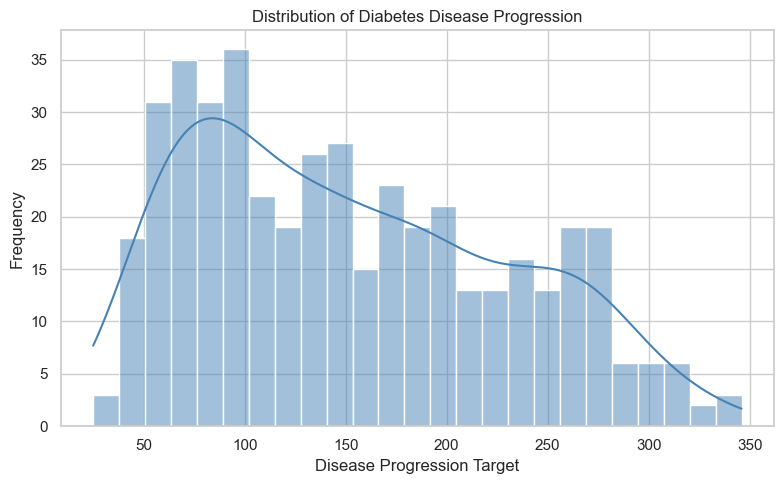

In [4]:
# Plot distribution of diabetes disease progression
plt.figure(figsize=(8, 5))

sns.histplot(
    df["target"],
    bins=25,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression Target")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

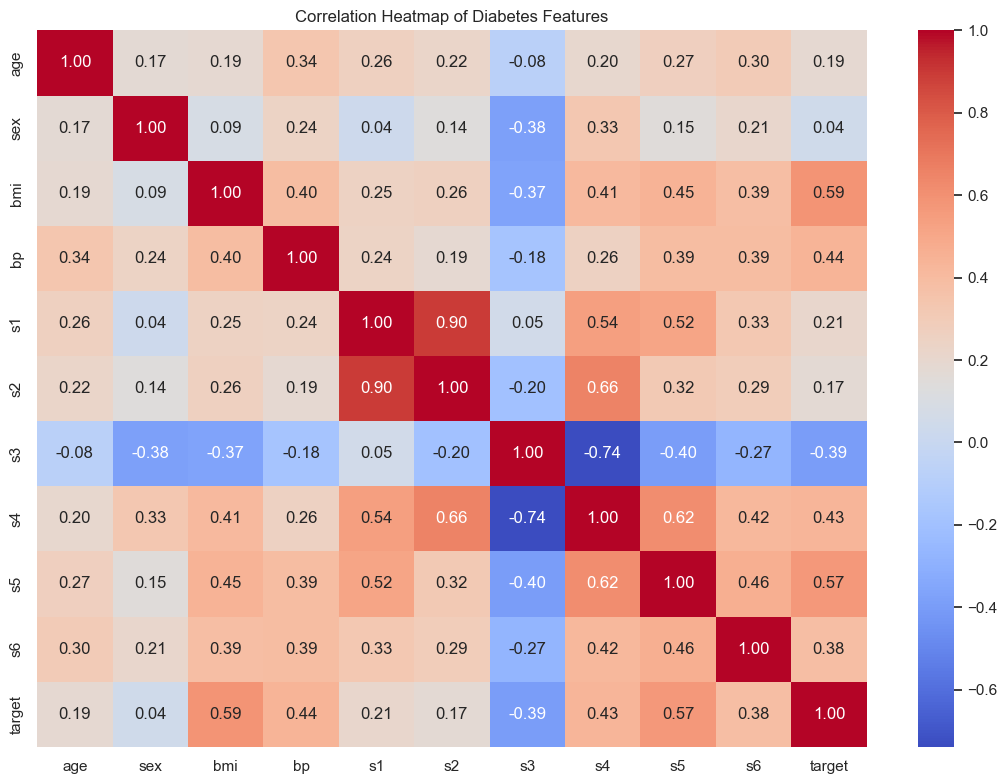

Feature Correlations with Target:
bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64


In [5]:
# Calculate the correlation matrix
correlation_matrix = df.corr()

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Features")
plt.tight_layout()
plt.show()

# Display correlations with target
print("Feature Correlations with Target:")
print(
    correlation_matrix["target"]
    .drop("target")
    .sort_values(ascending=False)
)

### Observations from Data Exploration

- The Diabetes dataset contains 442 observations, 10 numerical input features, and one target variable.
- The target variable exhibits a broad distribution, indicating considerable variation in disease progression.
- The correlation heatmap identifies relationships among the predictors and the target.
- The `bmi` and `s5` features show relatively strong positive correlations with disease progression, making them useful predictors.
- Correlations between some input features suggest that multicollinearity may influence regression coefficients, motivating the later use of regularization.

## Step 2: Simple Linear Regression

Simple Linear Regression uses one independent variable to predict a continuous dependent variable.

For this experiment, Body Mass Index (`bmi`) is selected as the independent variable because it shows a relatively strong relationship with the diabetes progression target.

The dataset is divided into 80% training data and 20% testing data. Performance is measured using MAE, MSE, RMSE, and R².

In [6]:
# Select BMI as the single independent feature
X_simple = df[["bmi"]]
y = df["target"]

# Split into training and testing sets
X_train_simple, X_test_simple, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.20,
    random_state=42
)

# Train the Simple Linear Regression model
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

# Predict training and testing values
simple_train_pred = simple_model.predict(X_train_simple)
simple_test_pred = simple_model.predict(X_test_simple)

print("Simple Linear Regression model trained successfully.")
print("Training samples:", len(X_train_simple))
print("Testing samples:", len(X_test_simple))

Simple Linear Regression model trained successfully.
Training samples: 353
Testing samples: 89


In [7]:
# Define a reusable evaluation function
def evaluate_model(name, y_true, predictions, train_true=None, train_predictions=None):
    mae = mean_absolute_error(y_true, predictions)
    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, predictions)

    train_r2 = (
        r2_score(train_true, train_predictions)
        if train_true is not None else np.nan
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Train_R2": train_r2
    })

    print(f"\n{name} Results:")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²: {r2:.4f}")
    print(f"Training R²: {train_r2:.4f}")


# Evaluate Simple Linear Regression
evaluate_model(
    "Simple Linear Regression",
    y_test,
    simple_test_pred,
    y_train,
    simple_train_pred
)


Simple Linear Regression Results:
MAE: 52.2600
MSE: 4061.8259
RMSE: 63.7325
R²: 0.2334
Training R²: 0.3657


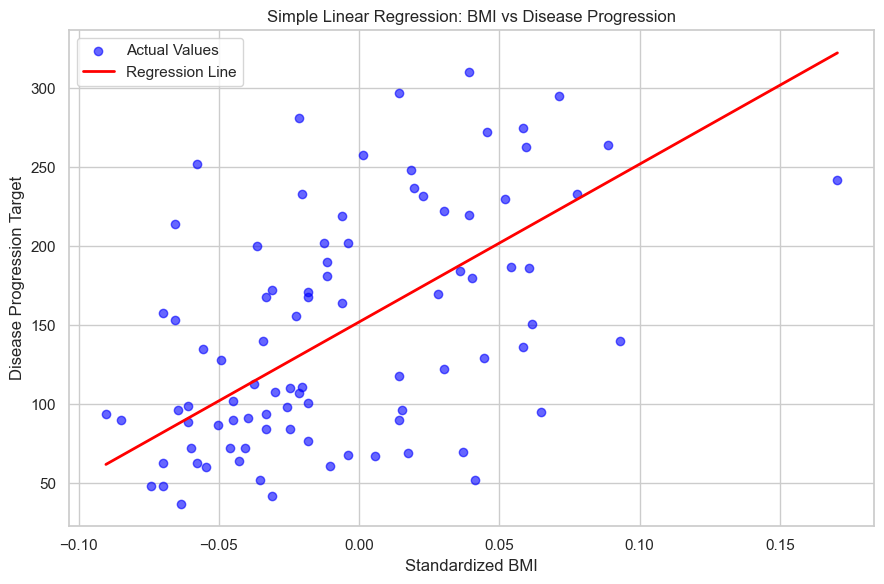

In [8]:
# Sort BMI values for displaying a continuous regression line
sorted_indices = np.argsort(X_test_simple["bmi"].values)

# Visualize observed and predicted values
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test_simple["bmi"],
    y_test,
    color="blue",
    alpha=0.6,
    label="Actual Values"
)

plt.plot(
    X_test_simple["bmi"].values[sorted_indices],
    simple_test_pred[sorted_indices],
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Simple Linear Regression: BMI vs Disease Progression")
plt.xlabel("Standardized BMI")
plt.ylabel("Disease Progression Target")
plt.legend()
plt.tight_layout()
plt.show()

### Simple Linear Regression Observations

The regression line indicates a positive relationship between BMI and diabetes progression. However, the observed target values show considerable scatter around the fitted line.

This suggests that BMI alone does not capture all the variation in disease progression.

The R² metric measures the proportion of test-set variation explained by the model. The error metrics quantify the typical magnitude of prediction errors.

A model using multiple patient characteristics may provide better predictive performance.

## Step 3: Multiple Linear Regression

Multiple Linear Regression uses several independent variables to predict one continuous target.

All 10 numerical features from the Diabetes dataset are included in this experiment.

The same 80/20 training and testing split and random state are used to ensure a fair comparison with Simple Linear Regression.

In [10]:
# Select all features
X_multiple = df.drop(columns=["target"])

# Split with the same random state as before
X_train, X_test, y_train, y_test = train_test_split(
    X_multiple,
    y,
    test_size=0.20,
    random_state=42
)

# Train the multiple regression model
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Generate predictions
multiple_train_pred = multiple_model.predict(X_train)
multiple_test_pred = multiple_model.predict(X_test)

# Evaluate model performance
evaluate_model(
    "Multiple Linear Regression",
    y_test,
    multiple_test_pred,
    y_train,
    multiple_train_pred
)


Multiple Linear Regression Results:
MAE: 42.7941
MSE: 2900.1936
RMSE: 53.8534
R²: 0.4526
Training R²: 0.5279


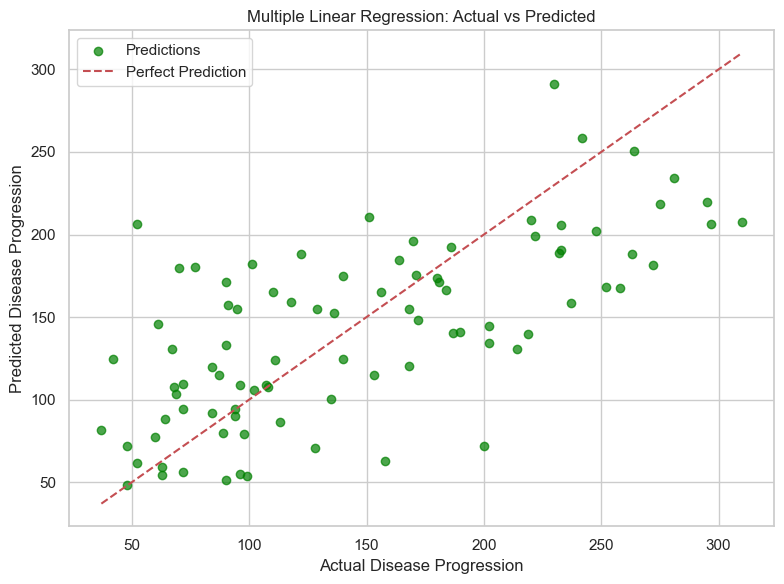

In [11]:
# Plot observed values against predicted values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    multiple_test_pred,
    alpha=0.7,
    color="green",
    label="Predictions"
)

# Plot ideal prediction line
min_val = min(y_test.min(), multiple_test_pred.min())
max_val = max(y_test.max(), multiple_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

### Multiple Linear Regression Observations

Multiple Linear Regression incorporates all 10 patient characteristics, providing more information than the BMI-only model.

The Actual vs Predicted graph illustrates how closely predictions follow the ideal diagonal line. Points closer to that line indicate more accurate predictions.

The comparison of test-set MAE, MSE, RMSE, and R² reveals whether including additional features improves predictive performance.

Multiple regression can capture more predictive information, but correlated predictors can make model coefficients unstable. Ridge and Lasso regularization will be explored to address this limitation.

## Step 4: Polynomial Regression

Polynomial Regression extends Linear Regression by introducing polynomial terms that can capture nonlinear relationships between an independent variable and the target.

For this experiment, BMI is used as the independent variable, and polynomial degrees 1, 2, 3, 5, 10, and 15 are evaluated.

Both training and testing performance are examined to investigate underfitting and overfitting.

- Underfitting occurs when a model is too simple to capture important patterns.
- Overfitting occurs when a model learns training-specific noise and fails to generalize to unseen data.
- Higher polynomial degrees increase model complexity but do not necessarily improve testing performance.

Polynomial Regression uses a pipeline to generate polynomial features, standardize them, and fit a Linear Regression model.

In [12]:
# Polynomial degrees to compare
degrees = [1, 2, 3, 5, 10, 15]

# Store polynomial performance
polynomial_results = []

# Train and evaluate each polynomial model
for degree in degrees:

    # Create polynomial regression pipeline
    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    # Train the model on BMI
    poly_model.fit(X_train_simple, y_train)

    # Predict training and testing values
    train_pred = poly_model.predict(X_train_simple)
    test_pred = poly_model.predict(X_test_simple)

    # Calculate evaluation metrics
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    mae = mean_absolute_error(y_test, test_pred)
    mse = mean_squared_error(y_test, test_pred)
    rmse = np.sqrt(mse)

    # Store results
    polynomial_results.append({
        "Degree": degree,
        "Train_R2": train_r2,
        "Test_R2": test_r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

# Display polynomial comparison
poly_df = pd.DataFrame(polynomial_results)

display(poly_df.round(4))

,Degree,Train_R2,Test_R2,MAE,MSE,RMSE
0,1,0.3657,0.2334,52.2600,4.061826e+03,63.7325
1,2,0.3665,0.2290,52.3839,4.085026e+03,63.9142
2,3,0.3667,0.2329,52.1814,4.064443e+03,63.7530
3,5,0.3707,0.2288,51.8846,4.085846e+03,63.9206
4,10,0.3870,0.1855,52.9589,4.315533e+03,65.6927
5,15,0.3918,-341.7145,194.0473,1.815753e+06,1347.4989


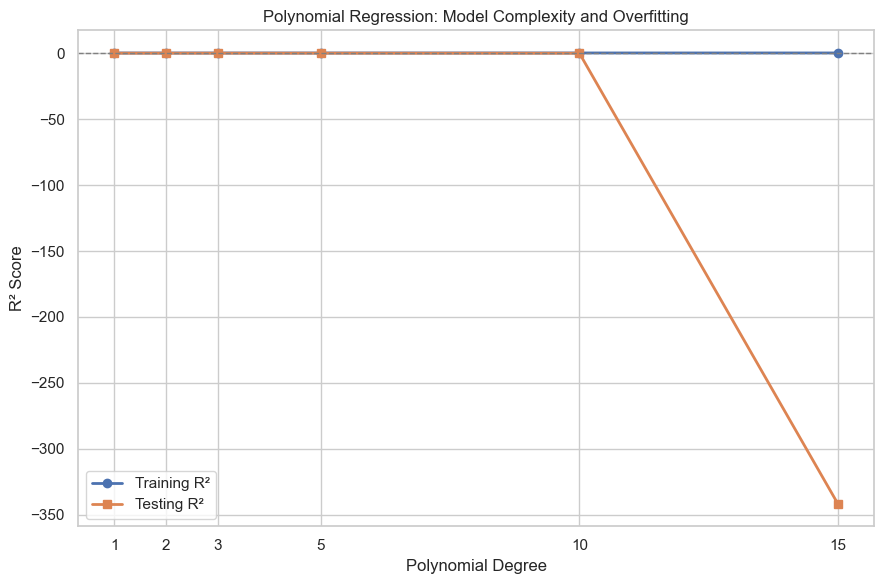

In [13]:
# Compare training and testing R² for different degrees
plt.figure(figsize=(9, 6))

plt.plot(
    poly_df["Degree"],
    poly_df["Train_R2"],
    marker="o",
    linewidth=2,
    label="Training R²"
)

plt.plot(
    poly_df["Degree"],
    poly_df["Test_R2"],
    marker="s",
    linewidth=2,
    label="Testing R²"
)

plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title("Polynomial Regression: Model Complexity and Overfitting")
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.xticks(degrees)
plt.legend()
plt.tight_layout()
plt.show()

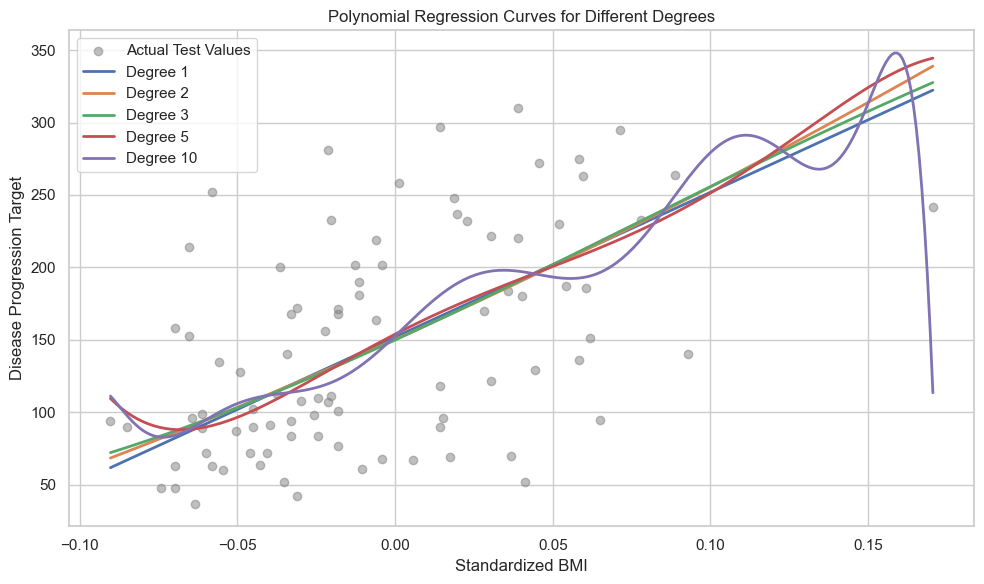

In [29]:
# Generate smooth BMI values for plotting
bmi_range = pd.DataFrame({
    "bmi": np.linspace(
        X_simple["bmi"].min(),
        X_simple["bmi"].max(),
        300
    )
})

plt.figure(figsize=(10, 6))

# Plot original test observations
plt.scatter(
    X_test_simple["bmi"],
    y_test,
    alpha=0.5,
    color="gray",
    label="Actual Test Values"
)

# Plot regression curves for selected degrees
for degree in [1, 2, 3, 5, 10]:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_train_simple, y_train)

    curve_predictions = model.predict(bmi_range)

    plt.plot(
        bmi_range["bmi"],
        curve_predictions,
        linewidth=2,
        label=f"Degree {degree}"
    )

plt.title("Polynomial Regression Curves for Different Degrees")
plt.xlabel("Standardized BMI")
plt.ylabel("Disease Progression Target")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Choose best degree based on test R² for descriptive comparison
# Note: Selecting a final model based on test performance
# would require separate validation data or cross-validation.
best_poly_row = poly_df.loc[poly_df["Test_R2"].idxmax()]
best_degree = int(best_poly_row["Degree"])

print("Best observed polynomial degree:", best_degree)
print("Test R²:", round(best_poly_row["Test_R2"], 4))
print("Test RMSE:", round(best_poly_row["RMSE"], 4))

# Add best observed polynomial model to comparison results
results.append({
    "Model": f"Polynomial Regression (Degree {best_degree})",
    "MAE": best_poly_row["MAE"],
    "MSE": best_poly_row["MSE"],
    "RMSE": best_poly_row["RMSE"],
    "R2": best_poly_row["Test_R2"],
    "Train_R2": best_poly_row["Train_R2"]
})

# Compare initial regression models
display(pd.DataFrame(results).round(4))

Best observed polynomial degree: 1
Test R²: 0.2334
Test RMSE: 63.7325


,Model,MAE,MSE,RMSE,R2,Train_R2
0,Simple Linear Regression,52.2600,4061.8259,63.7325,0.2334,0.3657
1,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526,0.5279
2,Polynomial Regression (Degree 1),52.2600,4061.8259,63.7325,0.2334,0.3657


### Polynomial Regression Observations

Polynomial Regression allows the model to capture nonlinear relationships between BMI and disease progression.

The training and testing R² plot demonstrates how model complexity affects performance.

At lower degrees, the model may underfit because it cannot capture more complex relationships. Increasing the polynomial degree can improve training performance, but very high degrees may produce unstable curves and reduce testing performance.

A large difference between training and testing R² suggests overfitting.

The polynomial models use only BMI, whereas Multiple Linear Regression uses all 10 features. Therefore, the comparison also reflects differences in the amount of predictive information available to each model.

The best observed polynomial degree and its metrics are displayed in the previous code cell. This is an exploratory test-set comparison rather than an unbiased model-selection procedure.

## Step 5: Regularization Using Ridge and Lasso Regression

Regularization introduces a penalty for large regression coefficients, helping control model complexity and reduce overfitting.

### Ridge Regression (L2 Regularization)

Ridge Regression adds a penalty based on the sum of squared coefficients. It tends to shrink coefficient values toward zero but usually does not eliminate them completely.

### Lasso Regression (L1 Regularization)

Lasso Regression adds a penalty based on the sum of the absolute coefficient values. It can shrink some coefficients exactly to zero, performing automatic feature selection.

### Effect of Alpha

Alpha controls the strength of the regularization penalty.

- A smaller alpha applies weaker regularization.
- A larger alpha applies stronger regularization.
- Excessively large alpha values can lead to underfitting.

The models use all 10 features. StandardScaler is applied within each training pipeline to ensure features are treated consistently.

Five-fold cross-validation on the training set is used to select alpha values without using the test set for tuning.

In [16]:
# Import tools for regularization hyperparameter selection
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Define candidate alpha values
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

# Create Ridge pipeline
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Create Lasso pipeline
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100000))
])

print("Regularization pipelines created successfully.")

Regularization pipelines created successfully.


In [17]:
# Perform cross-validation for Ridge Regression
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Fit on training data only
ridge_search.fit(X_train, y_train)

# Obtain best fitted Ridge model
ridge_model = ridge_search.best_estimator_

# Generate predictions
ridge_train_pred = ridge_model.predict(X_train)
ridge_test_pred = ridge_model.predict(X_test)

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])

# Evaluate Ridge Regression
evaluate_model(
    "Ridge Regression",
    y_test,
    ridge_test_pred,
    y_train,
    ridge_train_pred
)

Best Ridge alpha: 10

Ridge Regression Results:
MAE: 42.8568
MSE: 2875.7787
RMSE: 53.6263
R²: 0.4572
Training R²: 0.5248


In [18]:
# Perform cross-validation for Lasso Regression
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Fit on training data only
lasso_search.fit(X_train, y_train)

# Obtain best fitted Lasso model
lasso_model = lasso_search.best_estimator_

# Generate predictions
lasso_train_pred = lasso_model.predict(X_train)
lasso_test_pred = lasso_model.predict(X_test)

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])

# Evaluate Lasso Regression
evaluate_model(
    "Lasso Regression",
    y_test,
    lasso_test_pred,
    y_train,
    lasso_train_pred
)

Best Lasso alpha: 1

Lasso Regression Results:
MAE: 42.8030
MSE: 2824.5681
RMSE: 53.1467
R²: 0.4669
Training R²: 0.5225


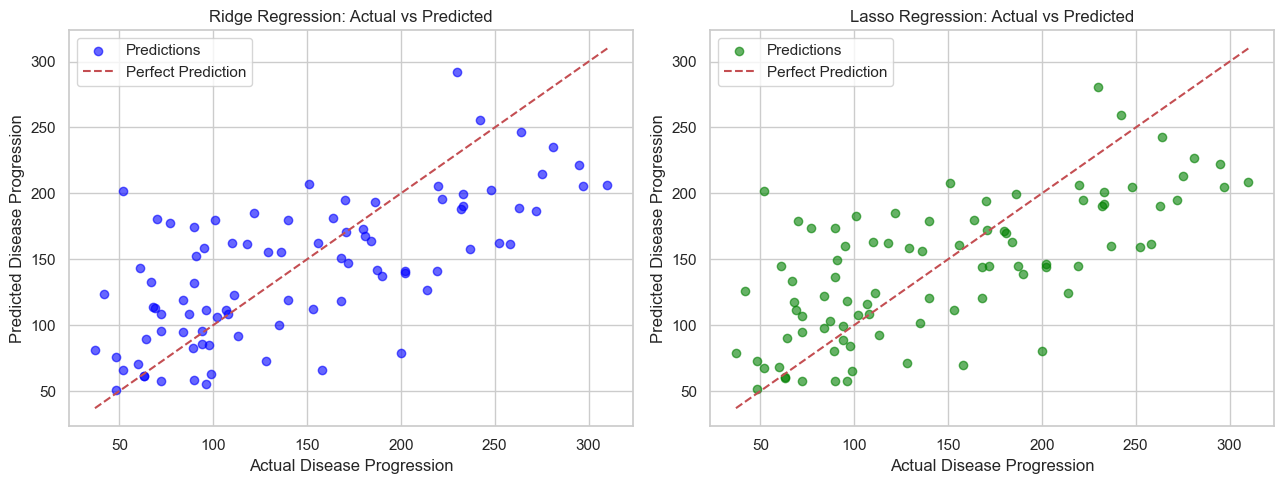

In [19]:
# Create separate charts for Ridge and Lasso
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models_to_plot = [
    ("Ridge Regression", ridge_test_pred, "blue"),
    ("Lasso Regression", lasso_test_pred, "green")
]

for ax, (name, predictions, color) in zip(axes, models_to_plot):

    ax.scatter(
        y_test,
        predictions,
        alpha=0.6,
        color=color,
        label="Predictions"
    )

    plot_min = min(y_test.min(), predictions.min())
    plot_max = max(y_test.max(), predictions.max())

    ax.plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        "r--",
        label="Perfect Prediction"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Disease Progression")
    ax.set_ylabel("Predicted Disease Progression")
    ax.legend()

plt.tight_layout()
plt.show()

,Feature,Ridge,Lasso
0,age,1.9313,0.6870
1,sex,-11.0282,-9.2975
2,bmi,25.6056,26.2192
3,bp,16.3042,15.6573
4,s1,-12.9342,-8.2282
5,s2,0.5382,-0.0000
6,s3,-6.1251,-9.0241
7,s4,8.5695,3.4209
8,s5,22.7493,22.6365
9,s6,2.9181,2.0986


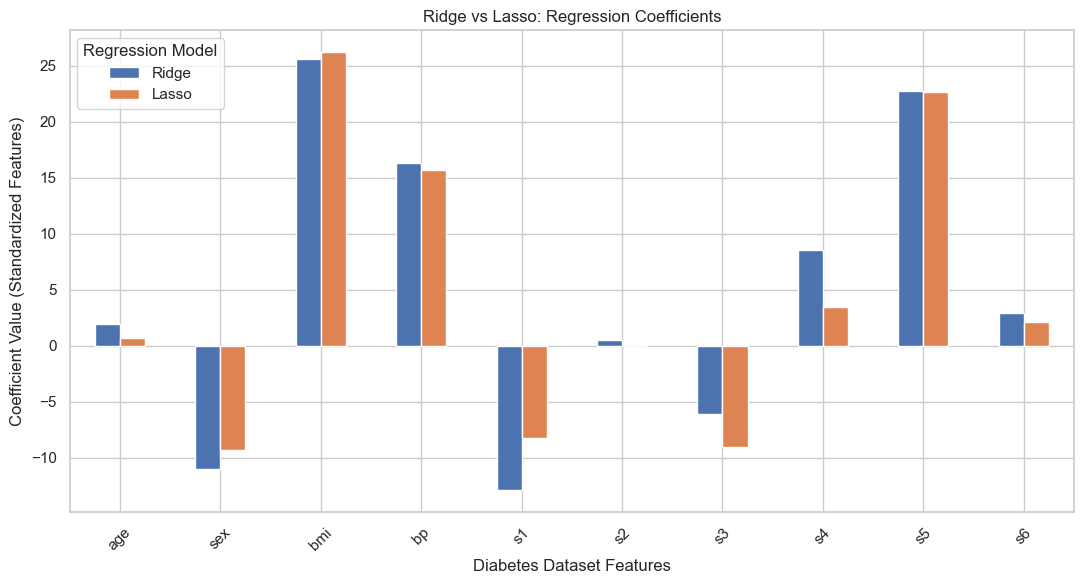

Number of coefficients reduced to zero by Lasso: 1


In [20]:
# Extract coefficients from both trained models
ridge_coefficients = ridge_model.named_steps["ridge"].coef_
lasso_coefficients = lasso_model.named_steps["lasso"].coef_

# Create comparison DataFrame
coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Ridge": ridge_coefficients,
    "Lasso": lasso_coefficients
})

display(coefficient_df.round(4))

# Visualize coefficient differences
coefficient_df.set_index("Feature").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Ridge vs Lasso: Regression Coefficients")
plt.xlabel("Diabetes Dataset Features")
plt.ylabel("Coefficient Value (Standardized Features)")
plt.xticks(rotation=45)
plt.legend(title="Regression Model")
plt.tight_layout()
plt.show()

# Count features removed by Lasso
zero_count = np.sum(np.isclose(lasso_coefficients, 0, atol=1e-8))

print("Number of coefficients reduced to zero by Lasso:", zero_count)

In [21]:
# Store training and testing results for different alpha values
alpha_results = []

for alpha in alpha_values:

    for model_name, estimator in [
        ("Ridge", Ridge(alpha=alpha)),
        ("Lasso", Lasso(alpha=alpha, max_iter=100000))
    ]:

        # Apply scaling within the pipeline
        model = make_pipeline(
            StandardScaler(),
            estimator
        )

        model.fit(X_train, y_train)

        # Generate predictions
        train_predictions = model.predict(X_train)
        test_predictions = model.predict(X_test)

        # Save metrics
        alpha_results.append({
            "Model": model_name,
            "Alpha": alpha,
            "Train_R2": r2_score(y_train, train_predictions),
            "Test_R2": r2_score(y_test, test_predictions),
            "Test_RMSE": np.sqrt(
                mean_squared_error(y_test, test_predictions)
            )
        })

alpha_df = pd.DataFrame(alpha_results)

display(alpha_df.round(4))

,Model,Alpha,Train_R2,Test_R2,Test_RMSE
0,Ridge,0.001,0.5279,0.4526,53.8533
1,Lasso,0.001,0.5279,0.4526,53.8517
2,Ridge,0.010,0.5279,0.4526,53.8523
3,Lasso,0.010,0.5279,0.4529,53.8365
4,Ridge,0.100,0.5279,0.4528,53.8429
5,Lasso,0.100,0.5272,0.4555,53.7087
6,Ridge,1.000,0.5276,0.4541,53.7775
7,Lasso,1.000,0.5225,0.4669,53.1467
8,Ridge,10.000,0.5248,0.4572,53.6263
9,Lasso,10.000,0.4651,0.4463,54.1649


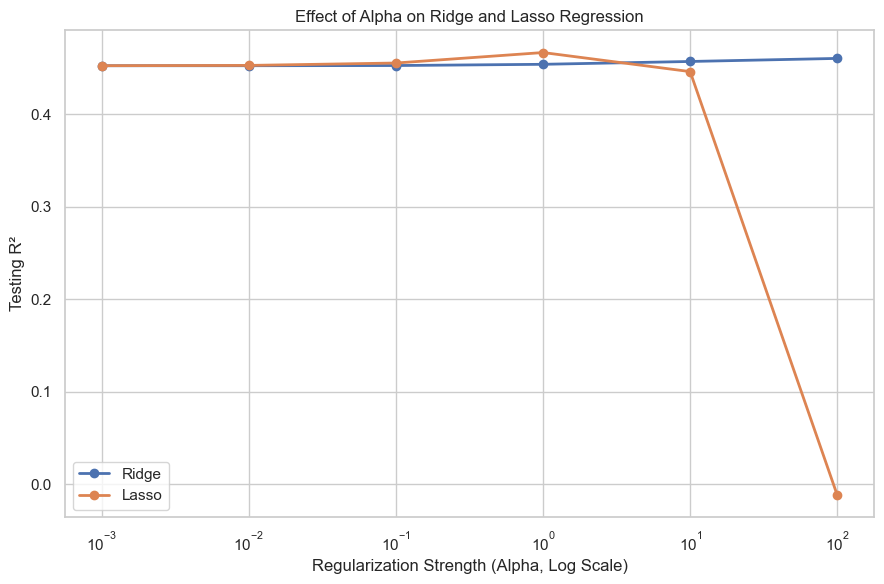

In [22]:
# Plot test R² for different alpha values
plt.figure(figsize=(9, 6))

for model_name in ["Ridge", "Lasso"]:

    subset = alpha_df[alpha_df["Model"] == model_name]

    plt.plot(
        subset["Alpha"],
        subset["Test_R2"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xscale("log")
plt.title("Effect of Alpha on Ridge and Lasso Regression")
plt.xlabel("Regularization Strength (Alpha, Log Scale)")
plt.ylabel("Testing R²")
plt.legend()
plt.tight_layout()
plt.show()

### Ridge and Lasso Regression Observations

Ridge and Lasso regularization help manage model complexity by penalizing large regression coefficients.

Ridge uses an L2 penalty, which generally reduces coefficient magnitudes while retaining all predictors.

Lasso uses an L1 penalty and can eliminate less useful features by reducing their coefficients to exactly zero.

The coefficient comparison chart illustrates how both methods distribute importance across the 10 input features.

The alpha analysis shows that different regularization strengths affect training and testing performance. Very strong regularization can reduce model flexibility and lead to underfitting.

Cross-validation is used to choose the final alpha values, reducing the risk of selecting hyperparameters based only on a single test split.

The final Ridge and Lasso results indicate whether regularization improves generalization compared with ordinary Multiple Linear Regression.

## Step 6: Model Comparison and Analysis

This section compares the regression models developed throughout the lab.

The performance evaluation includes:

1. Mean Absolute Error (MAE): Average absolute difference between actual and predicted values.
2. Mean Squared Error (MSE): Average squared prediction error.
3. Root Mean Squared Error (RMSE): Square root of MSE, expressed in the same units as the target.
4. R-squared (R²): Proportion of variation in the target explained by the model on the evaluated dataset.

Lower MAE, MSE, and RMSE values indicate better predictive accuracy.

Higher test R² generally indicates better prediction performance, although negative R² values are possible for poorly performing models.

Training R² is also considered when investigating possible overfitting.

In [23]:
# Combine regression results into one DataFrame
comparison_df = pd.DataFrame(results)

# Sort models from lowest to highest test RMSE
comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# Calculate the training-testing R² difference
comparison_df["R2_Gap"] = (
    comparison_df["Train_R2"] - comparison_df["R2"]
)

print("Final Regression Model Comparison:")
display(comparison_df.round(4))

# Identify model with lowest observed test RMSE
best_model = comparison_df.iloc[0]

print("\nModel with Lowest Observed Test RMSE:")
print("Model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 4))
print("MSE:", round(best_model["MSE"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("R²:", round(best_model["R2"], 4))

Final Regression Model Comparison:


,Model,MAE,MSE,RMSE,R2,Train_R2,R2_Gap
0,Lasso Regression,42.8030,2824.5681,53.1467,0.4669,0.5225,0.0557
1,Ridge Regression,42.8568,2875.7787,53.6263,0.4572,0.5248,0.0676
2,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526,0.5279,0.0753
3,Polynomial Regression (Degree 1),52.2600,4061.8259,63.7325,0.2334,0.3657,0.1324
4,Simple Linear Regression,52.2600,4061.8259,63.7325,0.2334,0.3657,0.1324



Model with Lowest Observed Test RMSE:
Model: Lasso Regression
MAE: 42.803
MSE: 2824.5681
RMSE: 53.1467
R²: 0.4669


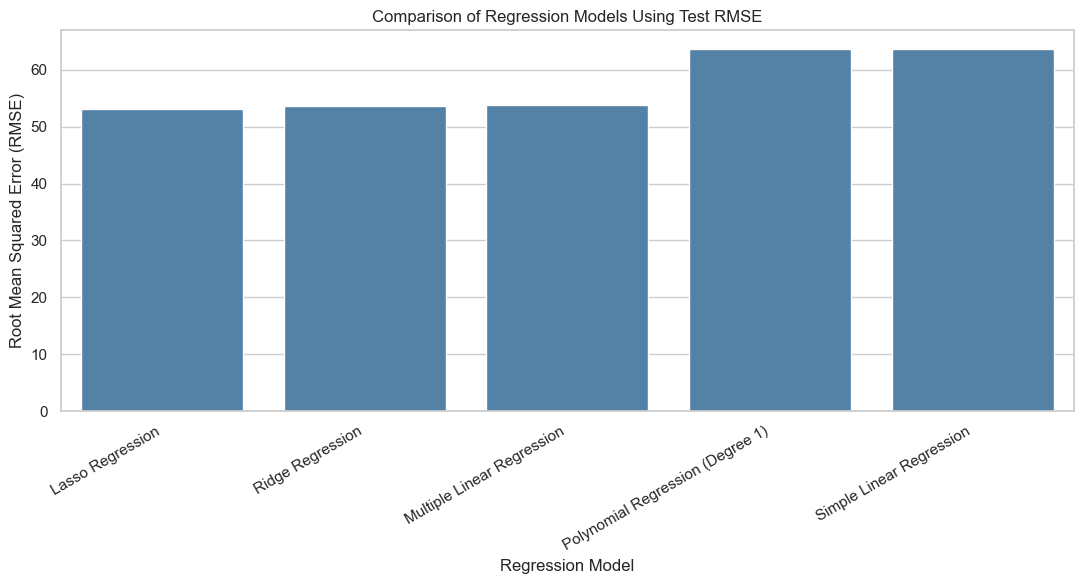

In [24]:
# Plot test RMSE of all evaluated models
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE",
    color="steelblue"
)

plt.title("Comparison of Regression Models Using Test RMSE")
plt.xlabel("Regression Model")
plt.ylabel("Root Mean Squared Error (RMSE)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


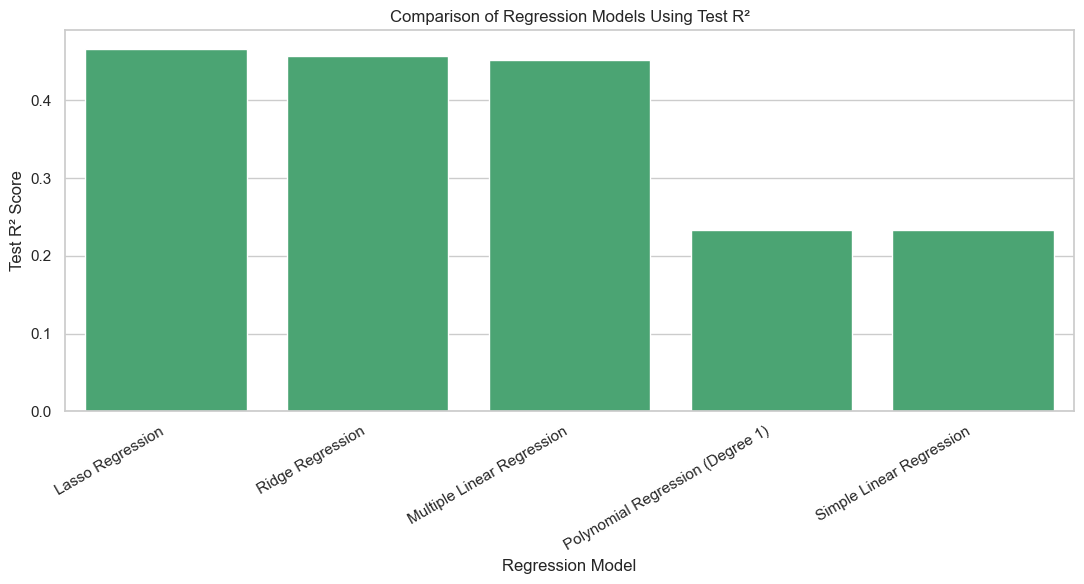

In [25]:
# Compare testing R² scores
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="R2",
    color="mediumseagreen"
)

plt.title("Comparison of Regression Models Using Test R²")
plt.xlabel("Regression Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

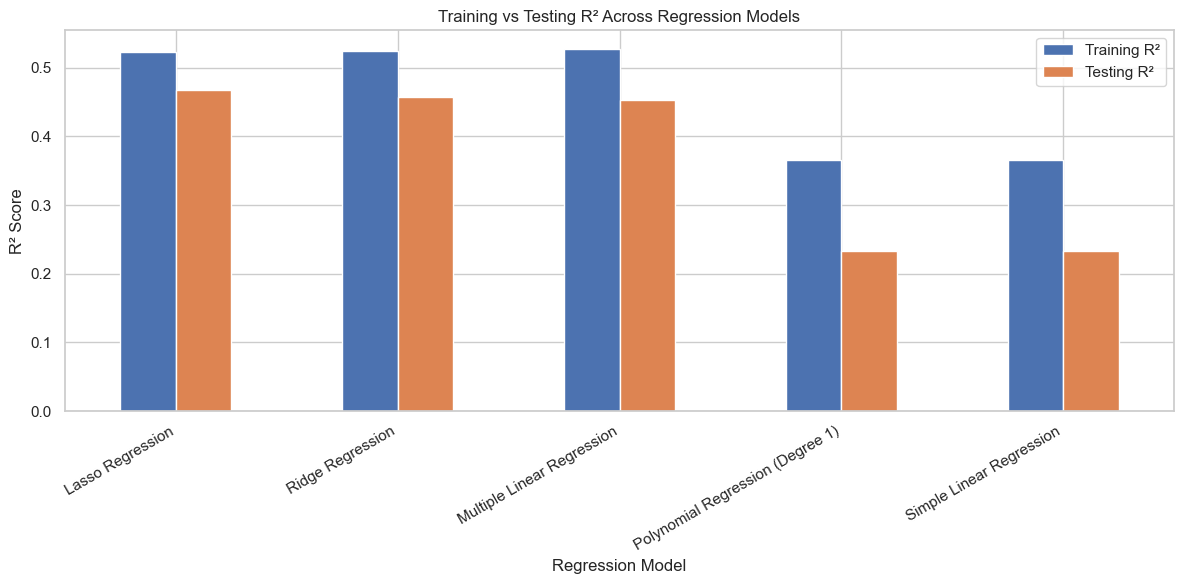

In [26]:
# Prepare performance comparison table
r2_comparison = comparison_df[
    ["Model", "Train_R2", "R2"]
].copy()

r2_comparison = r2_comparison.rename(columns={
    "Train_R2": "Training R²",
    "R2": "Testing R²"
})

# Plot training versus testing performance
r2_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Training vs Testing R² Across Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# Retrieve key model results
simple_row = comparison_df[
    comparison_df["Model"] == "Simple Linear Regression"
].iloc[0]

multiple_row = comparison_df[
    comparison_df["Model"] == "Multiple Linear Regression"
].iloc[0]

ridge_row = comparison_df[
    comparison_df["Model"] == "Ridge Regression"
].iloc[0]

lasso_row = comparison_df[
    comparison_df["Model"] == "Lasso Regression"
].iloc[0]

print("FINAL ANALYSIS")
print("-" * 55)

print("\n1. Simple vs Multiple Linear Regression")

if multiple_row["RMSE"] < simple_row["RMSE"]:
    print("Multiple Linear Regression achieved lower test RMSE.")
else:
    print("Simple Linear Regression achieved lower test RMSE.")

print("\n2. Polynomial Regression")
print(f"Best observed polynomial degree: {best_degree}")

high_degree = poly_df[
    poly_df["Degree"] == max(degrees)
].iloc[0]

print(f"Highest-degree training R²: {high_degree['Train_R2']:.4f}")
print(f"Highest-degree testing R²: {high_degree['Test_R2']:.4f}")

print("\n3. Regularization")

print(f"Ridge alpha: {ridge_search.best_params_['ridge__alpha']}")
print(f"Lasso alpha: {lasso_search.best_params_['lasso__alpha']}")
print(f"Ridge test RMSE: {ridge_row['RMSE']:.4f}")
print(f"Lasso test RMSE: {lasso_row['RMSE']:.4f}")

if ridge_row["RMSE"] < multiple_row["RMSE"]:
    print("Ridge improved test RMSE over Multiple Linear Regression.")
else:
    print("Ridge did not improve test RMSE over Multiple Linear Regression.")

if lasso_row["RMSE"] < multiple_row["RMSE"]:
    print("Lasso improved test RMSE over Multiple Linear Regression.")
else:
    print("Lasso did not improve test RMSE over Multiple Linear Regression.")

print("\n4. Overall Performance")
print(f"Lowest observed test RMSE: {best_model['Model']}")
print(f"RMSE: {best_model['RMSE']:.4f}")
print(f"R²: {best_model['R2']:.4f}")

FINAL ANALYSIS
-------------------------------------------------------

1. Simple vs Multiple Linear Regression
Multiple Linear Regression achieved lower test RMSE.

2. Polynomial Regression
Best observed polynomial degree: 1
Highest-degree training R²: 0.3918
Highest-degree testing R²: -341.7145

3. Regularization
Ridge alpha: 10
Lasso alpha: 1
Ridge test RMSE: 53.6263
Lasso test RMSE: 53.1467
Ridge improved test RMSE over Multiple Linear Regression.
Lasso improved test RMSE over Multiple Linear Regression.

4. Overall Performance
Lowest observed test RMSE: Lasso Regression
RMSE: 53.1467
R²: 0.4669


## Final Discussion and Conclusion

### 1. Performance of Different Regression Models

Simple Linear Regression establishes a baseline for predicting diabetes disease progression using BMI alone. Although BMI is related to disease progression, one predictor cannot capture all the factors affecting the target.

Multiple Linear Regression includes all 10 input features, allowing the model to use information from several patient characteristics. The performance comparison table provides evidence of whether this additional information improves predictions.

Polynomial Regression investigates nonlinear relationships between BMI and the target. Results show how changes in polynomial degree influence the balance between model flexibility and generalization.

### 2. Overfitting and Underfitting

Low-degree polynomial models may underfit because they cannot represent complex relationships.

High-degree polynomial models can produce more complex curves that fit the training data closely but perform poorly on unseen observations.

Comparing training and testing R² helps identify this behavior. A large training-testing performance gap can indicate overfitting.

### 3. Ridge and Lasso Regularization

Ridge and Lasso apply penalties to control coefficient magnitudes.

Ridge reduces coefficient values using L2 regularization, while Lasso can eliminate some predictors using L1 regularization.

The alpha parameter controls the strength of these penalties. Cross-validation helps select appropriate alpha values without tuning directly on test performance.

Regularization may improve testing performance and coefficient stability, but its effectiveness depends on the dataset and selected parameters.

### 4. Insights About the Diabetes Dataset

The Diabetes dataset contains multiple numerical patient characteristics associated with disease progression.

BMI and the `s5` feature have relatively strong positive correlations with the target.

However, prediction errors remain because the available features do not explain every aspect of disease progression.

Correlations and regression coefficients describe statistical relationships rather than proving causation.

### 5. Overall Conclusion

This lab demonstrated how Simple Linear Regression, Multiple Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression can be applied to a real dataset.

Evaluation using MAE, MSE, RMSE, and R² makes it possible to compare prediction accuracy.

Polynomial Regression illustrates how increasing model complexity can contribute to overfitting, while Ridge and Lasso demonstrate techniques for controlling complexity.

The model comparison table identifies the lowest observed test error among the evaluated models. Because the polynomial degree comparison examined test results, a separate validation approach would be necessary before claiming that the selected model is the best for future unseen data.

Overall, the experiment highlights the importance of selecting appropriate features, controlling model complexity, evaluating generalization, and interpreting results carefully.